# Module 2 Lab — Fraud Detection: Cost-Sensitive Learning, Drift & Explainability
**MSCA Doctoral Programme · Anomaly Detection · Module 2 of 3**

In Module 1, just before this, we asked *"is this point unusual?"* and measured detectors with precision, recall and PR-AUC.
Here we ask the question a bank actually pays for: **"should we stop this transaction, given what each mistake costs, and can we explain why?"**

**The plan, in five steps** (the same five parts as the talk):

| part | question | what you do |
|---|---|---|
| **A** · Score | what does the model see? | build features that describe the card's *behaviour*, split the data *in time* |
| **B** · Calibrate | what do SMOTE and class weights do? | train four variants, check that a probability means what it says |
| **C** · Decide | where do we put the threshold? | compare F1 with a rule that minimises **dollars** |
| **D** · Guard | what happens when fraudsters change? | watch a supervised model decay, and an unsupervised one help |
| **E** · Explain | why was *this* card blocked? | explain single alerts with **SHAP** |

**Dataset — why not Module 1's credit-card data?** The ULB credit-card dataset is PCA-anonymised (`V1…V28`).
A SHAP plot saying "flagged because V14 = −9.3" explains nothing to an investigator or an auditor.
We use the **Sparkov** simulated card-transaction dataset (Kaggle `kartik2112/fraud-detection`): ~1.85 M
transactions over 2019–2020 with **semantically meaningful** fields (amount, merchant category, timestamp,
cardholder and merchant location, date of birth). That lets us build real behavioural features and real explanations.

**How to run:** Colab or local Jupyter. By default the notebook uses a **synthetic look-alike** of Sparkov with the
**same schema**, so everyone sees the same results as on the slides, offline. Set `USE_KAGGLE = True` in the loader
cell to try the Kaggle data instead (every number will then differ).

> The pre-run outputs saved in this instructor copy come from the **synthetic data**. Into it we
> deliberately injected a **new fraud modus operandi from mid-2020** (daytime bursts, mid-size amounts,
> distant merchants), so the concept-drift story in Part D is visible. On the real Sparkov data the
> fraud pattern is stationary: Parts B, C and E transfer (several effects are even *stronger*), while in
> Part D the supervised model holds up and the unsupervised safety net costs more than it saves.
> Both outcomes are discussed in the read-outs.

**Time budget (1 hour):** setup, data & features ~10 min · Part B ~15 min · Part C ~15 min · Part D ~10 min · Part E ~10 min.

**How to work:** only **five cells, marked ✏️, ask you to write code** (B2, C1, C2, D2, E1), each a few lines with hints.
Everything else is ready to run: run it, look at the figure, and read the **Read-out** under it. Cells marked ⭐ are optional,
for fast groups or after class.


## 0 · Environment setup

In [1]:
# Portable setup: install anything missing (Colab or local), then import.
import importlib, subprocess, sys, warnings
warnings.filterwarnings("ignore")
def _ensure(pkgs):
    for mod, pip in pkgs:
        try:
            importlib.import_module(mod)
        except ImportError:
            print(f"installing {pip} ...")
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip], check=False)
_ensure([("sklearn", "scikit-learn"), ("xgboost", "xgboost"), ("shap", "shap"),
         ("imblearn", "imbalanced-learn"), ("seaborn", "seaborn"),
         ("pandas", "pandas"), ("numpy", "numpy"), ("matplotlib", "matplotlib")])

import os, time
from pathlib import Path
from typing import Callable
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import xgboost as xgb, shap

RNG = 42
np.random.seed(RNG)
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (9, 5)
print(f"xgboost {xgb.__version__} · shap {shap.__version__} · Environment ready.")

xgboost 3.2.0 · shap 0.49.1 · Environment ready.


## 1 · Data loader (synthetic Sparkov by default, Kaggle optional)

We **sample whole cards, never individual transactions**: per-card behavioural features (velocity,
amount-vs-history) are meaningless if you delete half of a card's history. Leave `USE_KAGGLE = False` to get
the same results as the slides; set it to `True` to try the Kaggle data (falls back to synthetic if unavailable).

In [2]:
USE_KAGGLE = False   # True = try the Kaggle Sparkov data; every number will then differ from the slides

CATS = ["entertainment", "food_dining", "gas_transport", "grocery_net", "grocery_pos", "health_fitness",
        "home", "kids_pets", "misc_net", "misc_pos", "personal_care", "shopping_net", "shopping_pos", "travel"]
CAT_BASE = dict(entertainment=60, food_dining=45, gas_transport=55, grocery_net=50, grocery_pos=95,
                health_fitness=50, home=60, kids_pets=55, misc_net=65, misc_pos=60, personal_care=40,
                shopping_net=75, shopping_pos=70, travel=110)          # typical $ per category
USECOLS = ["trans_date_trans_time", "cc_num", "category", "amt", "gender", "lat", "long",
           "city_pop", "dob", "merch_lat", "merch_long", "is_fraud"]

def _synthetic_sparkov(n_cards: int = 300, seed: int = RNG, drift: bool = True) -> pd.DataFrame:
    """Sparkov-schema simulator: 2 years of per-card legit spending + fraud *episodes*.
    Fraud MO "A" (night, big-ticket online/grocery) dominates until mid-2020; MO "B"
    (daytime velocity bursts, mid-size amounts, unusual categories, distant merchants)
    ramps in from 2020-06-15 -> a concept drift the supervised model never saw.
    drift=False gives the no-drift twin: identical cards, legit spending and episode times,
    but every episode keeps MO "A"."""
    rng, side = np.random.default_rng(seed), np.random.default_rng(seed + 1)
    t0, days = pd.Timestamp("2019-01-01"), 731

    def mo_a(r, start, lat, lon):
        k = r.integers(2, 9) + (4 if r.random() < 0.3 else 0)
        hrs = np.where(r.random(k) < 0.7, r.choice([22, 23, 0, 1, 2, 3], k), r.integers(8, 22, k))
        dd = np.floor(start) + r.integers(0, 2, k)
        ts_f = t0 + pd.to_timedelta(dd, "D") + pd.to_timedelta(hrs, "h") + pd.to_timedelta(r.integers(0, 3600, k), "s")
        cf = r.choice(["shopping_net", "misc_net", "grocery_pos", "shopping_pos"], k, p=[.35, .2, .3, .15])
        af = np.where(cf == "grocery_pos", r.normal(310, 25, k), np.exp(r.normal(6.6, 0.45, k)))
        return ts_f, cf, af, lat + r.normal(0, .5, k), lon + r.normal(0, .5, k), "A_night_bigticket"

    cat_pref = np.array([6, 7, 10, 3, 9, 6, 9, 8, 4, 6, 7, 6, 8, 3], float)
    hour_legit = np.array([1, .6, .5, .4, .4, .6, 1.5, 3, 4, 4.5, 5, 6, 7, 6.5, 6, 6, 6.5, 7, 7.5, 7, 6, 5, 3.5, 2])
    dts = t0 + pd.to_timedelta(np.arange(days), "D")
    day_w = np.where(dts.month == 12, 1.4, 1.0); day_w = day_w / day_w.sum()   # December rush
    rows = []
    for c in range(n_cards):
        lat, lon = rng.uniform(30, 47), rng.uniform(-120, -75)
        prof = dict(cc_num=4_000_000_000_000_000 + c * 7919, lat=lat, long=lon,
                    city_pop=int(np.exp(rng.normal(8.5, 2.0))), gender=rng.choice(["F", "M"]),
                    dob=t0 - pd.Timedelta(days=int(rng.uniform(18, 85) * 365.25)))
        rate, mult = np.exp(rng.normal(-0.1, 0.5)), np.exp(rng.normal(0, 0.35))   # txns/day, spend level
        p_cat = rng.dirichlet(cat_pref * 1.5)
        hp = hour_legit.copy()
        if rng.random() < 0.12:
            hp[[22, 23, 0, 1, 2, 3]] *= 6            # night owls -> realistic false positives
        hp /= hp.sum()
        n = rng.poisson(rate * days)
        d, h = rng.choice(days, n, p=day_w), rng.choice(24, n, p=hp)
        ts = t0 + pd.to_timedelta(d, "D") + pd.to_timedelta(h, "h") + pd.to_timedelta(rng.integers(0, 3600, n), "s")
        cat = rng.choice(len(CATS), n, p=p_cat)
        amt = np.array([CAT_BASE[CATS[k]] for k in cat]) * mult * np.exp(rng.normal(0, 0.7, n))
        big = rng.random(n) < 0.004
        amt[big] *= rng.uniform(5, 15, big.sum())  # legit big-ticket purchases
        sd = np.where(cat == CATS.index("travel"), 3.0, 0.5)
        rows.append(pd.DataFrame(dict(trans_date_trans_time=ts, category=[CATS[k] for k in cat], amt=amt,
                    merch_lat=lat + rng.normal(0, 1, n) * sd, merch_long=lon + rng.normal(0, 1, n) * sd,
                    is_fraud=0, fraud_mo="none", **prof)))
        for _ in range(rng.poisson(0.65)):          # fraud episodes on this card
            start = rng.uniform(0, days - 3)
            st = t0 + pd.Timedelta(days=start)
            p_b = np.clip((st - pd.Timestamp("2020-06-15")).days / 90, 0, 1) * 0.85
            if rng.random() >= p_b:                 # MO A
                ts_f, cf, af, mlat, mlon, mo = mo_a(rng, start, lat, lon)
            else:                                   # MO B
                k = rng.integers(4, 13)
                ts_f = st.normalize() + pd.Timedelta(hours=int(rng.integers(9, 15))) + \
                       pd.to_timedelta(np.sort(rng.uniform(0, 5 * 3600, k)), "s")
                cf = rng.choice(["grocery_net", "health_fitness", "home", "travel", "kids_pets", "personal_care"], k)
                af = np.array([CAT_BASE[x] for x in cf]) * mult * rng.uniform(1.5, 3.5, k)
                mlat, mlon, mo = lat + rng.normal(0, 6, k), lon + rng.normal(0, 6, k), "B_day_burst"
                if not drift:                       # twin: MO B draws above keep rng in step; the episode stays MO A
                    ts_f, cf, af, mlat, mlon, mo = mo_a(side, start, lat, lon)
            rows.append(pd.DataFrame(dict(trans_date_trans_time=ts_f, category=cf, amt=af, merch_lat=mlat,
                        merch_long=mlon, is_fraud=1, fraud_mo=mo, **prof)))
    df = pd.concat(rows, ignore_index=True)
    df["amt"] = df["amt"].clip(1, 30000).round(2)
    return df.sort_values("trans_date_trans_time").reset_index(drop=True)

def load_sparkov(n_cards: int = 350) -> pd.DataFrame:
    """Sparkov (Kaggle kartik2112/fraud-detection, train+test files = 2019-2020), sampled by card."""
    if USE_KAGGLE:
        try:
            import kagglehub
            path = Path(kagglehub.dataset_download("kartik2112/fraud-detection"))
            df = pd.concat([pd.read_csv(p, usecols=USECOLS) for p in sorted(path.glob("fraud*.csv"))],
                           ignore_index=True)
            df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
            df["dob"] = pd.to_datetime(df["dob"])
            keep = pd.Series(df["cc_num"].unique()).sample(n_cards, random_state=RNG)
            df = df[df["cc_num"].isin(keep)].sort_values("trans_date_trans_time").reset_index(drop=True)
            df["fraud_mo"] = np.where(df["is_fraud"] == 1, "unknown", "none")   # MO is not labelled in real data
            print(f"Loaded REAL Sparkov ({n_cards} cards): {df.shape}")
            return df
        except Exception as e:
            print(f"[fallback] real Sparkov unavailable ({type(e).__name__}); using synthetic.")
    df = _synthetic_sparkov()
    print(f"Loaded SYNTHETIC Sparkov-like data: {df.shape}")
    return df

raw = load_sparkov()
print("fraud rate: %.3f%%" % (100 * raw["is_fraud"].mean()))
raw.head()

Loaded SYNTHETIC Sparkov-like data: (225596, 13)
fraud rate: 0.555%


,trans_date_trans_time,category,amt,merch_lat,merch_long,is_fraud,fraud_mo,cc_num,lat,long,city_pop,gender,dob
0,2019-01-01 00:02:49,kids_pets,108.46,30.156518,-99.430014,0,none,4000000002051021,30.210191,-99.492910,4216,M,1979-10-09
1,2019-01-01 00:11:12,grocery_net,27.21,30.110333,-117.336204,0,none,4000000001164093,31.236897,-117.284421,95899,F,1953-09-01
2,2019-01-01 00:36:20,kids_pets,207.11,45.104423,-114.632848,0,none,4000000002003507,46.295297,-115.314849,9366,M,1939-02-09
3,2019-01-01 00:42:08,gas_transport,23.64,40.834870,-79.979271,0,none,4000000000277165,41.633315,-79.877020,8801,F,1944-01-13
4,2019-01-01 00:47:39,kids_pets,58.23,43.095420,-91.561233,0,none,4000000000118785,42.618570,-92.031744,485004,F,1968-06-05


---
## PART A · The domain: imbalance, time, and behaviour

### A1 · EDA — three questions that shape the whole pipeline
1. **How rare** is fraud? (decides metrics and the imbalance strategy)
2. **When** does it happen, and does that change over time? (decides the split and the drift plan)
3. **How much money** is involved? (decides the cost function: fraud is *not* equally expensive)

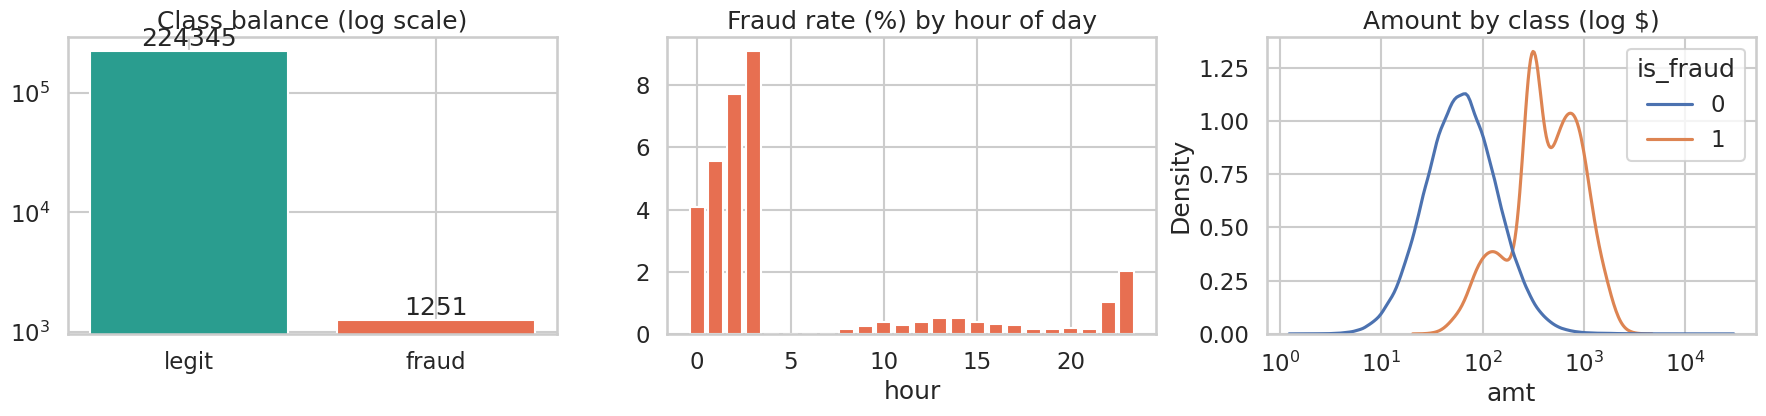

1251 frauds · total $687,717 · median $427 · top 10% of frauds = 26% of the $ lost


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
vc = raw["is_fraud"].value_counts().sort_index()
ax[0].bar(["legit", "fraud"], vc.values, color=["#2a9d8f", "#e76f51"]); ax[0].set_yscale("log")
ax[0].bar_label(ax[0].containers[0]); ax[0].set_title("Class balance (log scale)")
by_hour = raw.groupby(raw["trans_date_trans_time"].dt.hour)["is_fraud"].mean() * 100
ax[1].bar(by_hour.index, by_hour.values, color="#e76f51"); ax[1].set_title("Fraud rate (%) by hour of day")
ax[1].set_xlabel("hour")
sns.kdeplot(data=raw, x="amt", hue="is_fraud", common_norm=False, log_scale=True, ax=ax[2])
ax[2].set_title("Amount by class (log $)")
plt.tight_layout(); plt.show()

fraud_usd = raw.loc[raw.is_fraud == 1, "amt"]
print(f"{len(fraud_usd)} frauds · total ${fraud_usd.sum():,.0f} · median ${fraud_usd.median():,.0f} · "
      f"top 10% of frauds = {fraud_usd.nlargest(len(fraud_usd)//10).sum()/fraud_usd.sum():.0%} of the $ lost")

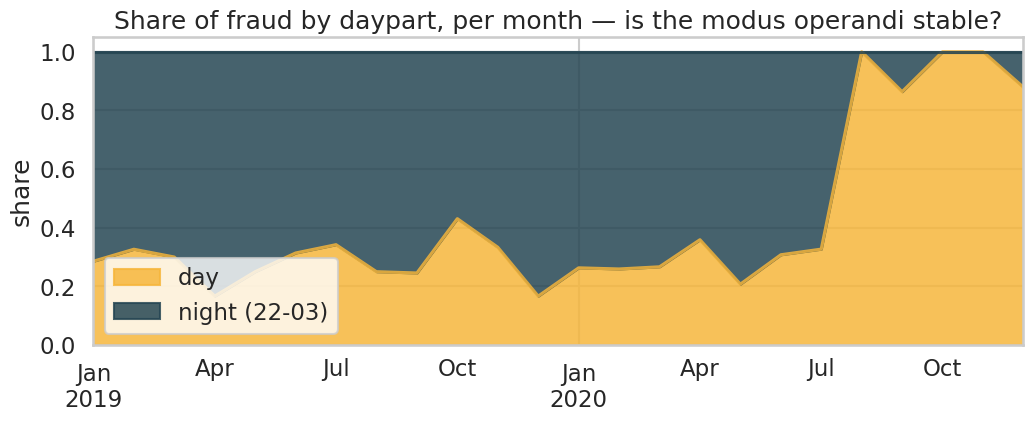

In [4]:
# Does the fraud pattern move over time?  (monthly fraud share by daypart)
f = raw[raw.is_fraud == 1].copy()
f["month"] = f["trans_date_trans_time"].dt.to_period("M").dt.to_timestamp()
f["daypart"] = np.where(f["trans_date_trans_time"].dt.hour.isin([22, 23, 0, 1, 2, 3]), "night (22-03)", "day")
mix = f.groupby(["month", "daypart"]).size().unstack(fill_value=0)
(mix.div(mix.sum(1), axis=0)).plot.area(figsize=(12, 4), color=["#f6b63c", "#264653"], alpha=.85)
plt.title("Share of fraud by daypart, per month — is the modus operandi stable?"); plt.ylabel("share")
plt.xlabel(""); plt.legend(loc="lower left"); plt.show()

**Read-out.** Fraud is ~0.5–0.7 % of transactions, concentrated in money (a minority of
frauds carry most of the dollars) and, at first, concentrated at night. On the synthetic data the
night share collapses after mid-2020: fraudsters changed their **modus operandi**. A model trained on
2019 will have to face that, which is why the split below is **temporal**, never random.

### A2 · Leakage-safe behavioural features
Raw fields say little; **behaviour relative to the card's own history** says a lot. The production rule:
every feature must be computable **at authorisation time**, using only the past. Concretely:
- `amt_ratio` = amount ÷ mean of this card's **previous** amounts (expanding mean, `shift(1)`);
- `n_txn_24h` = number of this card's transactions in the previous 24 h (velocity);
- `secs_since_last`, `dist_km` (cardholder home ↔ merchant), `first_time_cat` (first purchase in that category).

Read how `amt_ratio` and `n_txn_24h` are built below. Note the `shift(1)`: forgetting it puts the current amount into its own baseline, which is a subtle **look-ahead leak**.

In [5]:
def haversine_km(lat1, lon1, lat2, lon2) -> np.ndarray:
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Per-card behavioural features using ONLY information available at authorisation time."""
    d = df.sort_values(["cc_num", "trans_date_trans_time"]).copy()
    ts = d["trans_date_trans_time"]
    d["hour"] = ts.dt.hour
    d["age"] = ((ts - d["dob"]).dt.days / 365.25).round(1)
    d["is_male"] = (d["gender"] == "M").astype(int)
    d["dist_km"] = haversine_km(d["lat"], d["long"], d["merch_lat"], d["merch_long"])
    g = d.groupby("cc_num", sort=False)
    # amount vs. the card's OWN past (shift(1) => the current txn is not in its own baseline)
    past_mean = g["amt"].transform(lambda s: s.shift(1).expanding().mean())
    d["amt_ratio"] = (d["amt"] / past_mean).fillna(1.0)
    # velocity: txns in the previous 24h (rolling window includes the current row -> subtract 1)
    d["n_txn_24h"] = (d.set_index("trans_date_trans_time").groupby("cc_num", sort=False)["amt"]
                      .rolling("24h").count().to_numpy() - 1)
    d["secs_since_last"] = (g["trans_date_trans_time"].diff().dt.total_seconds()
                            .fillna(7 * 86400).clip(upper=7 * 86400))
    d["first_time_cat"] = (~d.duplicated(["cc_num", "category"])).astype(int)
    return d.sort_values("trans_date_trans_time").reset_index(drop=True)

t = time.time()
data = engineer_features(raw)
print(f"features in {time.time()-t:.1f}s")
data[["amt", "amt_ratio", "n_txn_24h", "secs_since_last", "dist_km", "first_time_cat", "is_fraud"]].groupby("is_fraud").median()

features in 0.3s


,amt,amt_ratio,n_txn_24h,secs_since_last,dist_km,first_time_cat
is_fraud,,,,,,
0,61.36,0.715441,1.0,55086.0,59.524974,0.0
1,426.82,4.230807,4.0,6689.0,73.310879,0.0


**Picture it.** Below is one card's history. Each dot is a purchase; the amber line is the card's average **so far**.
`amt_ratio` is simply *dot ÷ amber line*: the fraud episode (red) sits far above what this card usually spends.

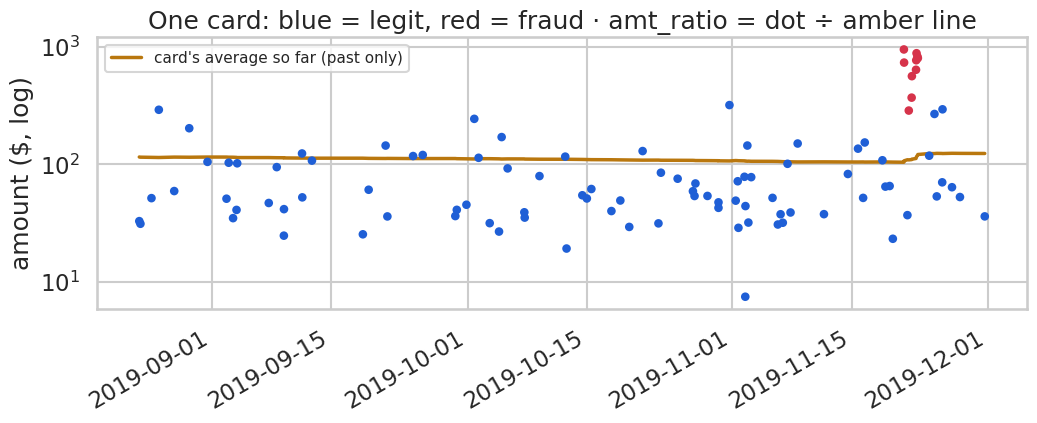

In [6]:
# One card's story: what amt_ratio sees
card = data.loc[data.is_fraud == 1, "cc_num"].value_counts().index[0]      # a card with a fraud episode
c = data[data.cc_num == card].set_index("trans_date_trans_time")
t_f = c.index[c.is_fraud == 1][0]
c = c[(c.index >= t_f - pd.Timedelta(days=90)) & (c.index <= t_f + pd.Timedelta(days=10))]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(c.index, c.amt / c.amt_ratio, color="#b9770e", lw=2.5, label="card's average so far (past only)")
ax.scatter(c.index, c.amt, s=22, c=np.where(c.is_fraud == 1, "#d6334a", "#1f5fd6"), zorder=3)
ax.set_yscale("log"); ax.set_ylabel("amount ($, log)"); ax.legend(loc="upper left", fontsize=11)
ax.set_title("One card: blue = legit, red = fraud · amt_ratio = dot ÷ amber line"); fig.autofmt_xdate(); plt.show()

### A3 · Temporal split — train · validate · test · *the future*
| split | period | used for |
|---|---|---|
| **train** | Jan–Oct 2019 | fitting models |
| **val** | Nov–Dec 2019 | choosing thresholds, checking calibration |
| **test** | Jan–Jun 2020 | honest offline evaluation (Parts B–C) |
| **future** | Jul–Dec 2020 | "deployment": what happens after go-live (Part D) |

Trees are invariant to monotone transforms of a feature, so XGBoost gets **raw dollars and kilometres**,
which keeps the SHAP plots readable. The category vocabulary is taken from **train only**.

In [7]:
FEATURES_NUM = ["amt", "amt_ratio", "hour", "n_txn_24h", "secs_since_last", "dist_km",
                "first_time_cat", "age", "is_male", "city_pop"]
when = data["trans_date_trans_time"]
split = np.select([when < "2019-11-01", when < "2020-01-01", when < "2020-07-01"],
                  ["train", "val", "test"], "future")
cat_vocab = sorted(data.loc[split == "train", "category"].unique())

def design_matrix(d: pd.DataFrame) -> pd.DataFrame:
    cats = pd.get_dummies(pd.Categorical(d["category"], categories=cat_vocab), prefix="cat", dtype=float)
    return pd.concat([d[FEATURES_NUM].reset_index(drop=True), cats.reset_index(drop=True)], axis=1)

X_all = design_matrix(data); y_all = data["is_fraud"].to_numpy(); amt_all = data["amt"].to_numpy()
S = {s: (split == s) for s in ["train", "val", "test", "future"]}
X_tr, y_tr, amt_tr = X_all[S["train"]], y_all[S["train"]], amt_all[S["train"]]
X_va, y_va, amt_va = X_all[S["val"]],   y_all[S["val"]],   amt_all[S["val"]]
X_te, y_te, amt_te = X_all[S["test"]],  y_all[S["test"]],  amt_all[S["test"]]
X_fu, y_fu, amt_fu = X_all[S["future"]], y_all[S["future"]], amt_all[S["future"]]
pd.DataFrame({s: [m.sum(), y_all[m].sum(), f"{y_all[m].mean():.3%}", f"${amt_all[m & (y_all == 1)].sum():,.0f}"]
              for s, m in S.items()}, index=["transactions", "frauds", "fraud rate", "fraud $"]).T

,transactions,frauds,fraud rate,fraud $
train,90450,471,0.521%,"$302,257"
val,22004,105,0.477%,"$71,484"
test,54322,321,0.591%,"$216,047"
future,58820,354,0.602%,"$97,930"


In [8]:
# Why not a random split?  Frauds come in EPISODES (several txns on one compromised card within hours).
# A random split puts siblings of the same episode in train and test -> the model "recognises" the episode.
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

XGB_PARAMS = dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=1, tree_method="hist",
                  random_state=RNG, n_jobs=-1)
pre = S["train"] | S["val"] | S["test"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_all[pre], y_all[pre], test_size=0.3,
                                              stratify=y_all[pre], random_state=RNG)
ap_random = average_precision_score(yr_te, xgb.XGBClassifier(**XGB_PARAMS).fit(Xr_tr, yr_tr).predict_proba(Xr_te)[:, 1])
ap_time = average_precision_score(y_te, xgb.XGBClassifier(**XGB_PARAMS).fit(X_tr, y_tr).predict_proba(X_te)[:, 1])
print(f"PR-AUC with RANDOM split: {ap_random:.3f}   vs   TEMPORAL split: {ap_time:.3f}")
print("The random split is optimistic: it leaks the future and the episode structure.")

PR-AUC with RANDOM split: 0.910   vs   TEMPORAL split: 0.869
The random split is optimistic: it leaks the future and the episode structure.


---
## PART B · Handling imbalance: class weights vs. SMOTE vs. cost weights

Fraud is under 1 % of transactions, and most tutorials "fix" that first. We train the *same* XGBoost in four ways:

| variant | in plain words |
|---|---|
| **unweighted** | every transaction counts once |
| **`scale_pos_weight`** $=w$ | every fraud counts $w$ times (here $w\approx$ 190) |
| **SMOTE** | invent extra frauds between pairs of real frauds |
| **cost weights** | every transaction counts by what a mistake on it costs (big frauds count more) |

Then we ask two questions: does the **ranking** improve (PR-AUC), and does the **probability** still mean what it says (calibration)?

### B1 · Helpers: metrics and the business cost

In [9]:
C_INV: float = 15.0   # $ cost of one manual review (analyst time + customer contact)
C_FRIC: float = 0.0   # $ extra cost of wrongly blocking a LEGIT customer (churn, call-centre); see challenge C5

def policy_cost(y: np.ndarray, flag: np.ndarray, amt: np.ndarray,
                c_inv: float = C_INV, c_fric: float = C_FRIC) -> float:
    """Total $ cost of a decision policy.
    flagged -> reviewed: pay c_inv (+ c_fric if the customer was legit); fraud is stopped.
    approved -> if it was fraud we lose the full amount (chargeback)."""
    flag, y = flag.astype(bool), y.astype(bool)
    return float(c_inv * flag.sum() + c_fric * (flag & ~y).sum() + amt[~flag & y].sum())

def savings(y, flag, amt, **kw) -> float:
    """Share of the 'approve everything' loss that the policy avoids (Bahnsen et al., 2014)."""
    return 1.0 - policy_cost(y, flag, amt, **kw) / policy_cost(y, np.zeros_like(y), amt, **kw)

def ranking_report(name: str, y, p) -> dict:
    return {"model": name, "PR_AUC": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "LogLoss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)),
            "mean_p / base_rate": p.mean() / y.mean()}

print(f"approve-all cost — val ${policy_cost(y_va, np.zeros_like(y_va), amt_va):,.0f}"
      f" · test ${policy_cost(y_te, np.zeros_like(y_te), amt_te):,.0f}")
print(f"flag-all cost    — test ${policy_cost(y_te, np.ones_like(y_te), amt_te):,.0f}  (reviewing everything is ruinous)")

approve-all cost — val $71,484 · test $216,047
flag-all cost    — test $814,830  (reviewing everything is ruinous)


### B2 · Train the four variants  ✏️
Fill in two lines:
1. `spw` = number of legit ÷ number of frauds in the **training** set, passed to `scale_pos_weight`;
2. the **cost weights**: a missed fraud costs its amount, a review costs `C_INV`, so a fraud row gets weight `amt − C_INV`
   (never below 0) and a legit row gets `C_INV`. Divide by the mean so the weights average 1.

In [10]:
from imblearn.over_sampling import SMOTE

models: dict[str, xgb.XGBClassifier] = {}
t = time.time()
models["unweighted"] = xgb.XGBClassifier(**XGB_PARAMS).fit(X_tr, y_tr)

spw = (y_tr == 0).sum() / (y_tr == 1).sum()            # n_neg / n_pos
models["scale_pos_weight"] = xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=spw).fit(X_tr, y_tr)

SMOTE_RATIO = 0.10                                      # minority : majority after resampling
smote = SMOTE(sampling_strategy=SMOTE_RATIO, k_neighbors=5, random_state=RNG)
X_sm, y_sm = smote.fit_resample(X_tr, y_tr)             # TRAIN ONLY: never resample before the split
models["SMOTE"] = xgb.XGBClassifier(**XGB_PARAMS).fit(X_sm, y_sm)

w_cost = np.where(y_tr == 1, np.maximum(amt_tr - C_INV, 0.0), C_INV + C_FRIC)
w_cost = w_cost / w_cost.mean()
models["cost-weighted"] = xgb.XGBClassifier(**XGB_PARAMS).fit(X_tr, y_tr, sample_weight=w_cost)
print(f"scale_pos_weight = {spw:.1f} · SMOTE grew train {len(X_tr):,} -> {len(X_sm):,} · fit {time.time()-t:.1f}s")

scale_pos_weight = 191.0 · SMOTE grew train 90,450 -> 98,976 · fit 3.7s


In [11]:
# What did SMOTE actually create?  Interpolating between two one-hot rows gives "0.4 grocery + 0.6 shopping".
synth = X_sm.iloc[len(X_tr):]
cat_cols = [c for c in X_tr.columns if c.startswith("cat_")]
frac = ((synth[cat_cols] % 1) > 1e-9).any(axis=1).mean()
print(f"{frac:.0%} of SMOTE frauds have a fractional merchant category, e.g.:")
synth.loc[((synth[cat_cols] % 1) > 1e-9).any(axis=1), ["amt", "hour", "is_male"] + cat_cols].head(3).round(2)

70% of SMOTE frauds have a fractional merchant category, e.g.:


,amt,hour,is_male,cat_entertainment,cat_food_dining,cat_gas_transport,cat_grocery_net,cat_grocery_pos,cat_health_fitness,cat_home,cat_kids_pets,cat_misc_net,cat_misc_pos,cat_personal_care,cat_shopping_net,cat_shopping_pos,cat_travel
90451,731.32,12,1,0.0,0.0,0.0,0.0,0.46,0.0,0.0,0.0,0.00,0.0,0.0,0.54,0.0,0.0
90452,921.87,17,1,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.81,0.0,0.0,0.19,0.0,0.0
90453,587.11,12,0,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,0.00,0.0,0.0,0.79,0.0,0.0


Those rows are **transactions that cannot exist** (half a gender, 0.4 of a grocery store, 14.6 o'clock). For mixed
data use `SMOTENC`, but the deeper problem remains: SMOTE assumes the minority class is *convex*
between neighbours, and in fraud the space between two fraud episodes is usually legitimate behaviour.

### B3 · Compare ranking quality *and* calibration

In [12]:
rep = pd.DataFrame([ranking_report(n, y_te, m.predict_proba(X_te)[:, 1]) for n, m in models.items()])
rep.round(4).set_index("model")

,PR_AUC,ROC_AUC,Brier,LogLoss,mean_p / base_rate
model,,,,,
unweighted,0.8688,0.9974,0.0019,0.0072,0.7722
scale_pos_weight,0.8621,0.9972,0.0030,0.0106,1.6217
SMOTE,0.8663,0.9976,0.0018,0.0067,1.0649
cost-weighted,0.8750,0.9980,0.0021,0.0075,1.3216


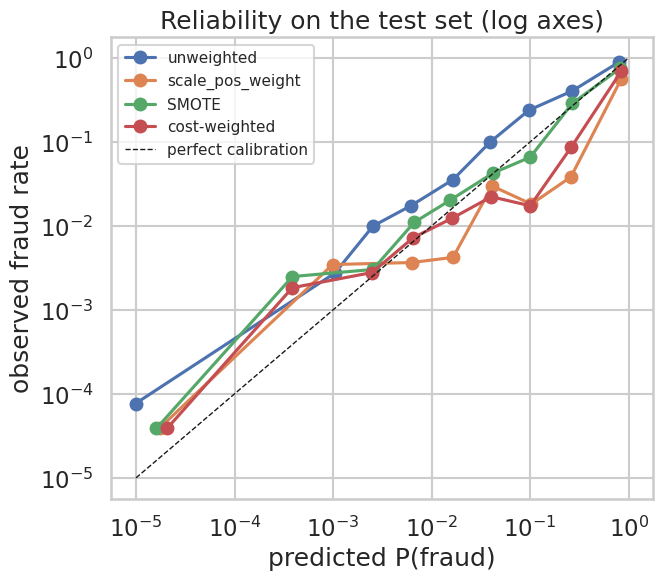

In [13]:
def reliability(y, p, edges=np.geomspace(1e-4, 1, 11), min_n=50):
    """Mean predicted vs. observed fraud rate per bin (log-spaced bins; empty or fraud-free bins skipped)."""
    b = np.digitize(p, edges[1:-1])
    return np.array([(p[b == k].mean(), y[b == k].mean()) for k in range(len(edges) - 1)
                     if (b == k).sum() >= min_n and y[b == k].sum() > 0]).T

fig, ax = plt.subplots(figsize=(7, 6))
for n, m in models.items():
    pp, pt = reliability(y_te, m.predict_proba(X_te)[:, 1])
    ax.plot(pp, pt, "o-", label=n)
ax.plot([1e-5, 1], [1e-5, 1], "k--", lw=1, label="perfect calibration"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("predicted P(fraud)"); ax.set_ylabel("observed fraud rate"); ax.legend(fontsize=11)
ax.set_title("Reliability on the test set (log axes)"); plt.show()

**How to read the plot.** A perfectly calibrated model sits on the dashed diagonal: of all transactions it scores at 1 %, about 1 % are fraud.
Points **below** the diagonal mean the model *over*-states the risk.

**Read-out — the central result of Part B.**
- **Ranking** (PR-AUC) barely moves for class weights and SMOTE. Re-weighting adds **no information**: boosting already sees every fraud.
- **Calibration** breaks: `scale_pos_weight` and SMOTE inflate the probabilities (look at `mean_p / base_rate`: 1 would be honest).
- So *"class weights help with imbalance"* really means *"class weights move the threshold"*. Fine for ranking, but wrong as soon as you
  use the number as a probability, which is exactly what Part C does.

### B4 · Fix the probabilities: Platt scaling
There is a textbook formula to undo the weights, but on boosted trees it over-corrects. The robust fix is to **recalibrate on
held-out data**: Platt scaling fits a tiny logistic regression $\sigma(a\cdot\text{logit}(p)+b)$ on the **validation** set.
Only two parameters, so it is stable even with ~100 frauds.

In [14]:
from sklearn.linear_model import LogisticRegression

def _logit(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))

def fit_platt(p_val: np.ndarray, y_val: np.ndarray) -> Callable[[np.ndarray], np.ndarray]:
    """Platt scaling on the logit of an existing score; returns a calibrator p -> p_calibrated."""
    lr = LogisticRegression(C=1e6).fit(_logit(p_val)[:, None], y_val)    # (almost) unregularised
    return lambda p: lr.predict_proba(_logit(p)[:, None])[:, 1]

calibrators = {n: fit_platt(m.predict_proba(X_va)[:, 1], y_va) for n, m in models.items()}   # fit on VAL
pd.DataFrame([ranking_report(f"{n} → Platt(val)", y_te, calibrators[n](m.predict_proba(X_te)[:, 1]))
              for n, m in models.items()]).round(4).set_index("model")

,PR_AUC,ROC_AUC,Brier,LogLoss,mean_p / base_rate
model,,,,,
unweighted → Platt(val),0.8688,0.9974,0.0019,0.0068,0.8440
scale_pos_weight → Platt(val),0.8621,0.9972,0.0019,0.0068,0.8392
SMOTE → Platt(val),0.8663,0.9976,0.0019,0.0068,0.8728
cost-weighted → Platt(val),0.8750,0.9980,0.0018,0.0065,0.8646


**Read-out.** After recalibration the unweighted, class-weighted and SMOTE variants become **practically indistinguishable**:
same ranking, same Brier score. On a strong learner, the imbalance treatment mostly changes *where the 0.5 threshold falls*.
The value is in calibration and in the decision rule (Part C).

**Why production teams usually prefer weights (or nothing) over SMOTE:** no synthetic rows to explain to an auditor, no impossible
category mixtures, nothing extra to compute at every retrain. SMOTE can still help learners that **cannot take weights** (e.g. k-NN)
on low-dimensional, continuous data. Evidence: Elor & Averbuch-Elor (2022); van den Goorbergh et al. (2022, JAMIA); Carriero et al. (2025),
who show that for flexible ML models, too, imbalance corrections harm calibration.

---
## PART C · From scores to decisions: minimising the business cost

A score is not a decision. A review costs money ($C_{inv}$ = \$15 here) and a missed fraud costs its **amount**. So, for each transaction:

$$\underbrace{p\cdot \text{amt}}_{\text{expected loss if we approve}} \;>\; \underbrace{C_{inv}}_{\text{cost of a review}} \quad\Longrightarrow\quad \text{flag it}$$

That is the **Bayes-optimal rule** (Elkan, 2001). Two examples: a \$2,000 purchase is worth reviewing from $p$ = 0.75 %; a \$20 purchase never is,
because even a certain fraud loses only \$20 − \$15. The threshold is **different for every transaction**, and nothing is tuned on labels.
It only needs a **calibrated** $p$, which is why Part B mattered. (With a friction cost $C_{fric}$ for bothering a legit customer, the
right-hand side becomes $C_{inv} + (1-p)\,C_{fric}$.)

We compare it with the usual alternatives: the default 0.5 threshold, and one global threshold tuned on validation for F1 or for cost.

### C1 · F1-optimal vs. cost-optimal threshold  ✏️
Try 400 global thresholds on the **validation** set. For each, compute F1 and the dollar cost. You write the two curves
and pick the two best thresholds; the plot and the test evaluation are ready.

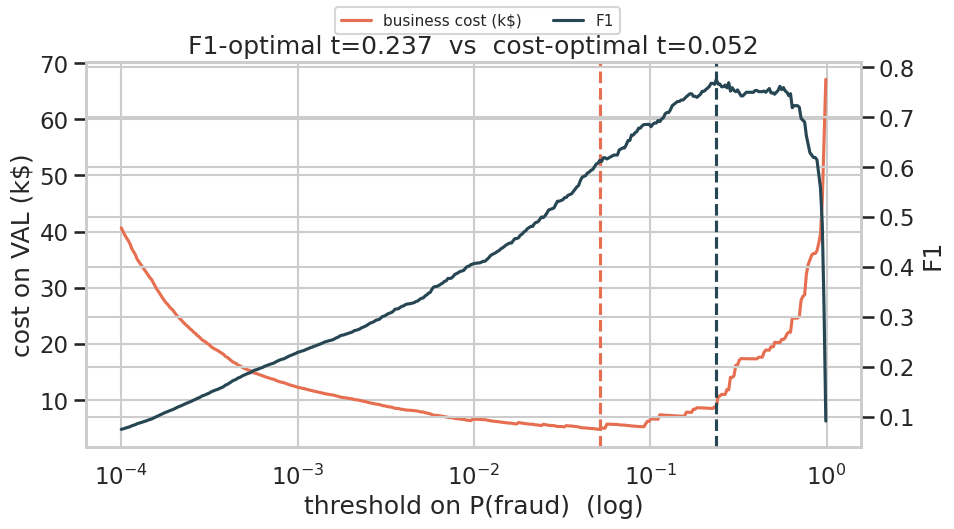

F1-optimal    t=0.2370 | TEST cost $   34,705 | alerts  337 | recall 0.81 | savings 83.9%
cost-optimal  t=0.0517 | TEST cost $   18,488 | alerts  552 | recall 0.93 | savings 91.4%


In [15]:
from sklearn.metrics import f1_score
p_va_raw = models["unweighted"].predict_proba(X_va)[:, 1]
p_te_raw = models["unweighted"].predict_proba(X_te)[:, 1]
p_va, p_te = calibrators["unweighted"](p_va_raw), calibrators["unweighted"](p_te_raw)   # Platt-calibrated
grid = np.unique(np.r_[np.geomspace(1e-4, 0.99, 400), 0.5])
f1_curve = np.array([f1_score(y_va, p_va >= t, zero_division=0) for t in grid])
cost_curve = np.array([policy_cost(y_va, p_va >= t, amt_va) for t in grid])
t_f1, t_cost = grid[f1_curve.argmax()], grid[cost_curve.argmin()]

fig, ax1 = plt.subplots(figsize=(10, 5)); ax2 = ax1.twinx()
ax1.plot(grid, cost_curve / 1e3, color="#e76f51", label="business cost (k$)")
ax2.plot(grid, f1_curve, color="#264653", label="F1")
ax1.axvline(t_cost, color="#e76f51", ls="--"); ax2.axvline(t_f1, color="#264653", ls="--")
ax1.set_xscale("log"); ax1.set_xlabel("threshold on P(fraud)  (log)"); ax1.set_ylabel("cost on VAL (k$)"); ax2.set_ylabel("F1")
ax1.set_title(f"F1-optimal t={t_f1:.3f}  vs  cost-optimal t={t_cost:.3f}")
fig.legend(loc="upper center", ncol=2, fontsize=11); plt.show()

for name, t_ in [("F1-optimal", t_f1), ("cost-optimal", t_cost)]:
    flag = p_te >= t_
    print(f"{name:13s} t={t_:.4f} | TEST cost ${policy_cost(y_te, flag, amt_te):>9,.0f} | "
          f"alerts {flag.sum():>4} | recall {flag[y_te == 1].mean():.2f} | savings {savings(y_te, flag, amt_te):.1%}")

**Read-out.** The F1 optimum sits far to the right: F1 treats a missed $1,200 fraud and a missed $3 fraud as the
same error, and it treats a $15 review as being as bad as a missed fraud. The cost optimum accepts **many more alerts** because each review is
cheap relative to the average fraud. Optimising F1 here leaves real money on the table.

### C2 · The Bayes-optimal rule  ✏️
Write `bayes_flag` (one line: the formula above). The table that compares it with the other policies is ready.
Look at what happens when you feed it **raw** vs. **Platt-calibrated** probabilities.

In [16]:
def bayes_flag(p: np.ndarray, amt: np.ndarray, c_inv: float = C_INV, c_fric: float = C_FRIC) -> np.ndarray:
    """Flag iff expected loss of approving (p*amt) > expected cost of flagging (c_inv + (1-p)*c_fric)."""
    return p * amt > c_inv + (1.0 - p) * c_fric

p_spw_raw = models["scale_pos_weight"].predict_proba(X_te)[:, 1]
policies = {
    "approve all":                         np.zeros_like(y_te, bool),
    "unweighted @ 0.5 (raw)":              p_te_raw >= 0.5,
    "unweighted @ F1-opt (val)":           p_te >= t_f1,
    "unweighted @ cost-opt (val)":         p_te >= t_cost,
    "unweighted + Bayes (raw p)":          bayes_flag(p_te_raw, amt_te),
    "unweighted + Bayes (Platt p)":        bayes_flag(p_te, amt_te),
    "scale_pos_weight @ 0.5":              p_spw_raw >= 0.5,
    "scale_pos_weight + Bayes (raw p)":    bayes_flag(p_spw_raw, amt_te),
    "scale_pos_weight + Bayes (Platt p)":  bayes_flag(calibrators["scale_pos_weight"](p_spw_raw), amt_te),
    "cost-weighted @ 0.5":                 models["cost-weighted"].predict_proba(X_te)[:, 1] >= 0.5,
}
pol = pd.DataFrame([{"policy": k, "cost_$": policy_cost(y_te, f, amt_te), "savings": savings(y_te, f, amt_te),
                     "alerts": int(f.sum()), "recall": f[y_te == 1].mean(),
                     "$_recall": amt_te[f & (y_te == 1)].sum() / amt_te[y_te == 1].sum(),
                     "precision": (f & (y_te == 1)).sum() / max(f.sum(), 1)} for k, f in policies.items()])
pol.sort_values("cost_$").round(3).set_index("policy")

,cost_$,savings,alerts,recall,$_recall,precision
policy,,,,,,
scale_pos_weight + Bayes (Platt p),15126.54,0.930,648,0.947,0.975,0.469
unweighted + Bayes (Platt p),15148.17,0.930,632,0.944,0.974,0.479
scale_pos_weight + Bayes (raw p),17118.04,0.921,969,0.969,0.988,0.321
unweighted + Bayes (raw p),18021.83,0.917,530,0.925,0.953,0.560
unweighted @ cost-opt (val),18488.03,0.914,552,0.928,0.953,0.540
scale_pos_weight @ 0.5,21137.25,0.902,487,0.919,0.936,0.606
cost-weighted @ 0.5,23011.46,0.893,391,0.866,0.921,0.711
unweighted @ F1-opt (val),34704.94,0.839,337,0.810,0.863,0.772
unweighted @ 0.5 (raw),68501.73,0.683,224,0.632,0.698,0.906


**Read-out.**
- **Calibrated probabilities + Bayes rule** give the lowest cost, with **no threshold tuned on labels**. The rule stops a higher share of fraud
  **dollars** than of fraud **counts**: it spends reviews where the money is.
- The rule is only as good as its probabilities. On **raw** `scale_pos_weight` output it over-flags (the weights inflated $p$).
  After **Platt** recalibration the weighted and unweighted models land in the same place.
- The **F1-optimal** threshold is among the most expensive "reasonable" policies, and **0.5 on an unweighted model** is a disaster.
  `scale_pos_weight @ 0.5` looks much better only because the weights quietly moved the threshold, which illustrates B3.
- The **cost-weighted model @ 0.5** builds the money into *training*. It is competitive, but its outputs are no longer probabilities.
  Most teams keep a calibrated model and put the money in the decision rule, where finance can change $C_{inv}$ without retraining.
  Vanderschueren et al. (2022) find the same on 9 real datasets: the decision rule matters more than the training trick.

### C3 · Are the differences real? Card-level bootstrap
Transactions of one card are not independent, so we resample **cards**, not rows.

In [17]:
def card_bootstrap_diff(cards: np.ndarray, y, amt, flag_a, flag_b, n_boot: int = 2000, seed: int = RNG):
    """95% CI of cost(A) - cost(B), resampling whole cards (cluster bootstrap)."""
    per_txn = lambda f: C_INV * f + C_FRIC * (f & (y == 0)) + amt * (~f & (y == 1))
    diff = pd.Series(per_txn(flag_a) - per_txn(flag_b)).groupby(cards).sum().to_numpy()
    rng = np.random.default_rng(seed)
    boots = diff[rng.integers(0, len(diff), (n_boot, len(diff)))].sum(1)
    return diff.sum(), np.percentile(boots, [2.5, 97.5])

cards_te = data.loc[S["test"], "cc_num"].to_numpy()
REF = "unweighted + Bayes (Platt p)"
for a in ["unweighted @ 0.5 (raw)", "unweighted @ F1-opt (val)", "unweighted @ cost-opt (val)",
          "scale_pos_weight + Bayes (raw p)", "scale_pos_weight + Bayes (Platt p)"]:
    d, (lo, hi) = card_bootstrap_diff(cards_te, y_te, amt_te, policies[a], policies[REF])
    verdict = "significant" if lo > 0 or hi < 0 else "within noise"
    print(f"cost[{a}] − cost[{REF}] = ${d:>8,.0f}   95% CI [${lo:>8,.0f}, ${hi:>8,.0f}]  → {verdict}")

cost[unweighted @ 0.5 (raw)] − cost[unweighted + Bayes (Platt p)] = $  53,354   95% CI [$  32,362, $  78,288]  → significant
cost[unweighted @ F1-opt (val)] − cost[unweighted + Bayes (Platt p)] = $  19,557   95% CI [$   9,236, $  32,194]  → significant
cost[unweighted @ cost-opt (val)] − cost[unweighted + Bayes (Platt p)] = $   3,340   95% CI [$    -333, $   8,184]  → within noise
cost[scale_pos_weight + Bayes (raw p)] − cost[unweighted + Bayes (Platt p)] = $   1,970   95% CI [$    -720, $   4,146]  → within noise
cost[scale_pos_weight + Bayes (Platt p)] − cost[unweighted + Bayes (Platt p)] = $     -22   95% CI [$  -1,032, $     891]  → within noise


Be honest about what the data can resolve. With a few hundred test frauds, some differences between *sensible* cost-aware
policies are **within noise** (check which ones on your run), while the gap to F1-tuned or 0.5-threshold policies is robust.
Report intervals, not just point estimates.

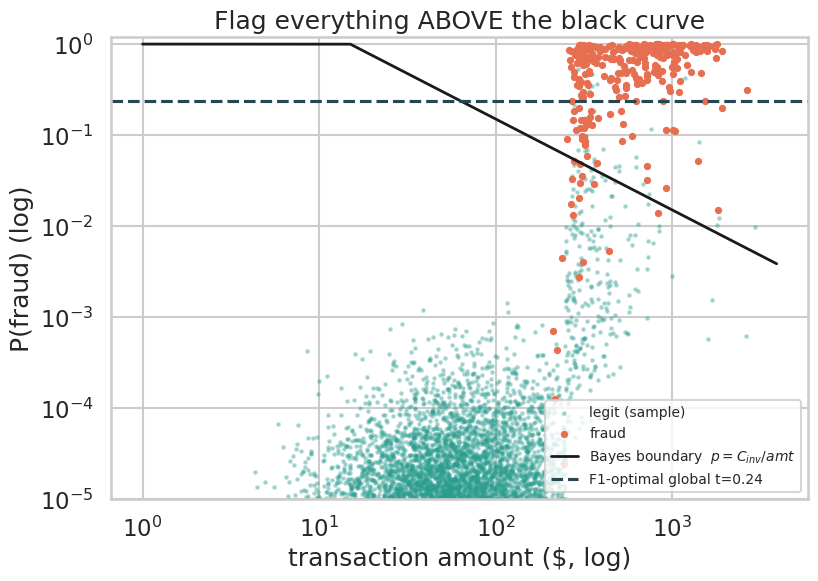

In [18]:
# The decision boundary in (amount, probability) space
fig, ax = plt.subplots(figsize=(9, 6))
sel = np.random.default_rng(RNG).choice(np.flatnonzero(y_te == 0), 6000, replace=False)
ax.scatter(amt_te[sel], p_te[sel], s=4, alpha=.3, color="#2a9d8f", label="legit (sample)")
ax.scatter(amt_te[y_te == 1], p_te[y_te == 1], s=14, color="#e76f51", label="fraud")
a_grid = np.geomspace(1, amt_te.max(), 300)
ax.plot(a_grid, np.clip(C_INV / a_grid, 0, 1), "k-", lw=2, label=r"Bayes boundary  $p = C_{inv}/amt$")
ax.axhline(t_f1, color="#264653", ls="--", label=f"F1-optimal global t={t_f1:.2f}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-5, 1.2)
ax.set_xlabel("transaction amount ($, log)"); ax.set_ylabel("P(fraud) (log)"); ax.legend(fontsize=10, loc="lower right")
ax.set_title("Flag everything ABOVE the black curve"); plt.show()

### C4 · Sensitivity: what if a review costs more?
Business inputs are uncertain. Show the decision-maker how the policy moves with $C_{inv}$.

In [19]:
rows = []
for c in [2, 5, 10, 15, 25, 50, 100]:
    f = bayes_flag(p_te, amt_te, c_inv=c)
    rows.append({"C_inv": c, "alerts": int(f.sum()), "recall": f[y_te == 1].mean(),
                 "$_recall": amt_te[f & (y_te == 1)].sum() / amt_te[y_te == 1].sum(),
                 "savings": savings(y_te, f, amt_te, c_inv=c)})
pd.DataFrame(rows).round(3).set_index("C_inv")

,alerts,recall,$_recall,savings
C_inv,,,,
2,1176,0.978,0.992,0.981
5,898,0.969,0.987,0.967
10,736,0.960,0.983,0.949
15,632,0.944,0.974,0.930
25,525,0.925,0.960,0.900
50,416,0.863,0.922,0.825
100,342,0.813,0.889,0.731


### C5 · ⭐ Challenges
1. **Customer friction.** Set `C_FRIC = 10` (a falsely blocked customer costs $10 in churn/call-centre time). Re-run C1–C2.
   Which policies change most, and why does the Bayes rule adapt automatically?
2. **Analyst capacity.** The team can review only **K = 2 alerts per day** (our card sample sees ~300 transactions/day, so this is
   a budget of ~0.7 % of volume, below the ~3 alerts/day the Bayes rule wants). Rank by $p$ vs. by **expected loss** $p\cdot\text{amt}$
   and compare the dollars stopped. *(Hint: group the test set by calendar day; take the top-K per day.)*
3. **Recovery rate.** If 30 % of approved fraud is later recovered via chargeback, how does the formula change?

In [20]:
# Solution to challenge 2 (capacity-constrained ranking)
def stopped_dollars_with_capacity(score: np.ndarray, k_per_day: int = 2) -> float:
    day = data.loc[S["test"], "trans_date_trans_time"].dt.date.to_numpy()
    rank = pd.Series(score).groupby(day).rank(ascending=False, method="first").to_numpy()
    flag = rank <= k_per_day
    return amt_te[flag & (y_te == 1)].sum()

for name, s in [("rank by p", p_te), ("rank by p·amt (expected loss)", p_te * amt_te)]:
    print(f"{name:32s} stops ${stopped_dollars_with_capacity(s):,.0f} of ${amt_te[y_te == 1].sum():,.0f}")

rank by p                        stops $110,988 of $216,047
rank by p·amt (expected loss)    stops $123,104 of $216,047


---
## PART D · After go-live: concept drift, supervised vs. unsupervised

Our supervised model only knows **fraud that has already been labelled**, and fraudsters adapt. Labels also arrive **late**
(with the chargeback, often 30–90 days later) and mostly for what we **flagged**.

An **unsupervised** detector, like Module 1's Isolation Forest, needs no fraud labels: it flags what does not look like *normal*
behaviour, whatever the fraud looks like. Can it cover the supervised model's blind spot?

### D1 · Isolation Forest on behavioural features
Same detector as in Module 1, trained on the 2019 transactions **without labels**. Two small preparation steps: heavy-tailed
features get a `log`, and the hour becomes a point on a circle (so 23:00 and 01:00 are close).

In [21]:
from sklearn.ensemble import IsolationForest

def if_features(d: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "log_amt": np.log1p(d["amt"]), "log_amt_ratio": np.log(d["amt_ratio"].clip(lower=1e-3)),
        "log_n_txn_24h": np.log1p(d["n_txn_24h"]), "log_secs_since_last": np.log1p(d["secs_since_last"]),
        "log_dist_km": np.log1p(d["dist_km"]), "first_time_cat": d["first_time_cat"],
        "hour_sin": np.sin(2 * np.pi * d["hour"] / 24), "hour_cos": np.cos(2 * np.pi * d["hour"] / 24),
    }).reset_index(drop=True)

U_all = if_features(data)
iso = IsolationForest(n_estimators=300, max_samples=512, random_state=RNG, n_jobs=-1).fit(U_all[S["train"]])  # no labels
if_score = -iso.score_samples(U_all)                       # higher = more anomalous
p_xgb_all = models["unweighted"].predict_proba(X_all)[:, 1]
pd.DataFrame([{"split": s, "XGB PR_AUC": average_precision_score(y_all[m], p_xgb_all[m]),
               "IF PR_AUC": average_precision_score(y_all[m], if_score[m])} for s, m in S.items() if s != "train"]
            ).round(3).set_index("split")

,XGB PR_AUC,IF PR_AUC
split,,
val,0.849,0.286
test,0.869,0.471
future,0.198,0.412


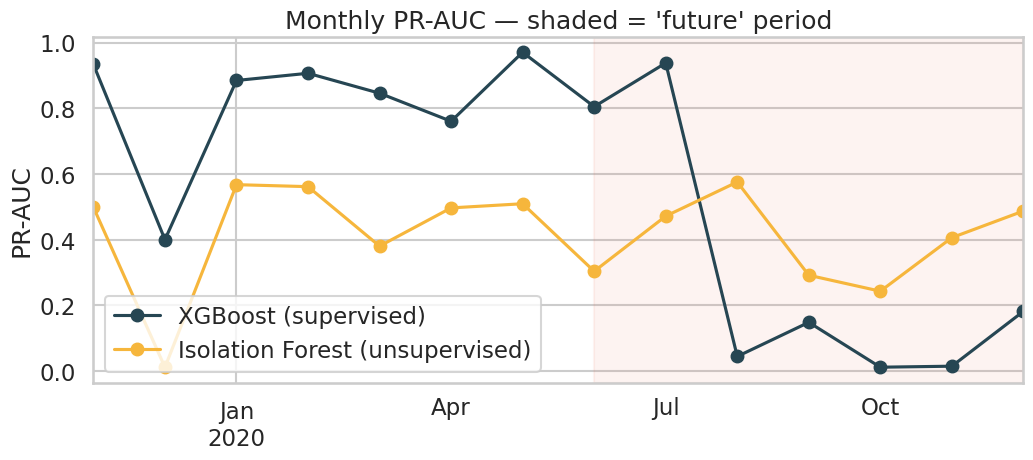

future · A_night_bigticket  XGB PR-AUC 0.833 · IF PR-AUC 0.236
future · B_day_burst        XGB PR-AUC 0.014 · IF PR-AUC 0.352


In [22]:
# Monthly PR-AUC after training: the drift picture
month = data["trans_date_trans_time"].dt.to_period("M")
post = (S["val"] | S["test"] | S["future"])
mon = (pd.DataFrame({"m": month[post], "y": y_all[post], "xgb": p_xgb_all[post], "iso": if_score[post]})
       .groupby("m").apply(lambda g: pd.Series({"XGBoost (supervised)": average_precision_score(g.y, g.xgb),
                                                "Isolation Forest (unsupervised)": average_precision_score(g.y, g.iso),
                                                "n_fraud": g.y.sum()})))
mon.index = mon.index.to_timestamp()
ax = mon.drop(columns="n_fraud").plot(marker="o", figsize=(12, 4.5), color=["#264653", "#f6b63c"])
ax.axvspan(pd.Timestamp("2020-06-16"), mon.index[-1] + pd.Timedelta(days=15), color="#e76f51", alpha=.08)
ax.set_xlabel(""); ax.set_ylabel("PR-AUC"); ax.set_title("Monthly PR-AUC — shaded = 'future' period"); plt.show()

if (data["fraud_mo"] != "unknown").any():                   # MO is known only for the synthetic data
    mo = data.loc[S["future"], "fraud_mo"].to_numpy()
    for k in sorted(set(mo) - {"none"}):
        s = (mo == k) | (y_fu == 0)
        print(f"future · {k:18s} XGB PR-AUC {average_precision_score(y_fu[s], p_xgb_all[S['future']][s]):.3f} · "
              f"IF PR-AUC {average_precision_score(y_fu[s], if_score[S['future']][s]):.3f}")

**Read-out (synthetic data).** Before the change, the supervised model wins clearly: labels are worth a lot. After the change, it is
almost blind to MO "B", because it learned *night + big ticket*. Isolation Forest never learned what fraud looks like, only
what normal looks like. It keeps flagging velocity bursts at distant merchants. **Neither model alone is the answer.**

**Read-out (real Sparkov data).** There is no MO change: XGBoost stays strong all year, and Isolation Forest is weak
(PR-AUC ≈ 0.1). Sparkov fraud is a *learnable pattern* more than a *behavioural outlier*. Keep that in mind for D3.

Also look at December 2019: both curves dip. The legitimate Christmas rush (more, larger purchases) is a *seasonal* shift
in normal behaviour that makes frauds harder to separate. Not all drift is adversarial.

### D2 · Would input monitoring have warned us?  ✏️ (Population Stability Index)
Banks monitor their inputs with the **PSI**: cut a feature into 10 bins using the training data, then compare the share of
transactions in each bin, then (reference, $e_b$) vs. now (actual, $a_b$):
$$\text{PSI}=\sum_{b}(a_b-e_b)\ln\frac{a_b}{e_b}$$
Rule of thumb: < 0.1 stable · 0.1–0.25 moderate · > 0.25 major shift.

In [23]:
def psi(expected: np.ndarray, actual: np.ndarray, n_bins: int = 10, eps: float = 1e-4) -> float:
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, eps, None), np.clip(a, eps, None)
    return float(np.sum((a - e) * np.log(a / e)))

feats = ["amt", "amt_ratio", "hour", "n_txn_24h", "dist_km", "secs_since_last"]
tr_all, fu_all = data[S["train"]], data[S["future"]]
tr_fr, fu_fr = tr_all[tr_all.is_fraud == 1], fu_all[fu_all.is_fraud == 1]
pd.DataFrame({"PSI · all transactions": [psi(tr_all[f], fu_all[f]) for f in feats],
              "PSI · frauds only": [psi(tr_fr[f], fu_fr[f]) for f in feats]}, index=feats).round(3)

,PSI · all transactions,PSI · frauds only
amt,0.000,2.151
amt_ratio,0.002,1.819
hour,0.000,2.103
n_txn_24h,0.007,0.201
dist_km,0.000,2.628
secs_since_last,0.005,0.805


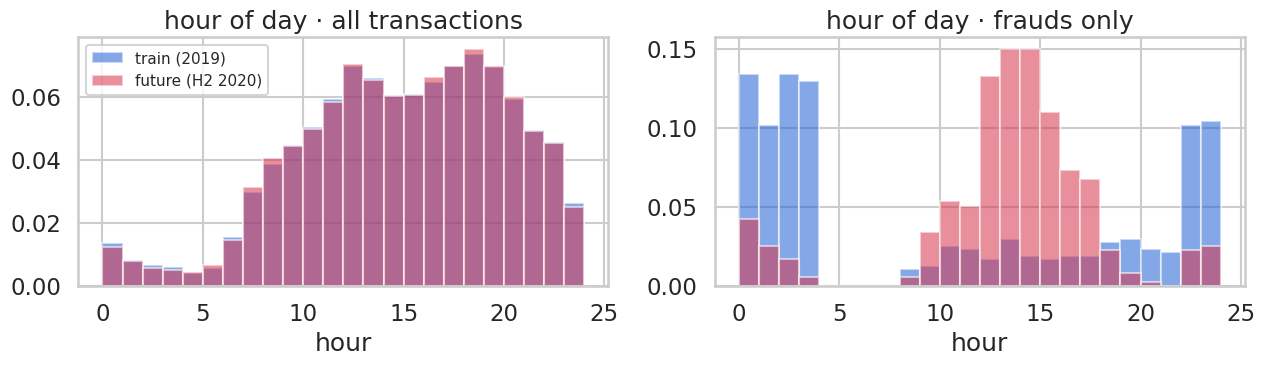

In [24]:
# What PSI sees: the hour of day, train (2019) vs. future (H2 2020)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (lab, tr_, fu_) in zip(ax, [("all transactions", tr_all, fu_all), ("frauds only", tr_fr, fu_fr)]):
    a.hist(tr_["hour"], bins=24, range=(0, 24), density=True, alpha=.55, color="#1f5fd6", label="train (2019)")
    a.hist(fu_["hour"], bins=24, range=(0, 24), density=True, alpha=.55, color="#d6334a", label="future (H2 2020)")
    a.set_title(f"hour of day · {lab}"); a.set_xlabel("hour")
ax[0].legend(fontsize=11); plt.tight_layout(); plt.show()

**Read-out — a subtle but important result (synthetic data).** On all transactions the PSI is tiny: fraud is < 1 % of traffic, so even a
complete change of fraud behaviour barely moves $P(x)$. (On the real data both columns are small: there was nothing to detect.) This is **real drift** (in $P(y\mid x)$) without visible **virtual drift**
(in $P(x)$). Unlabelled input monitoring would have stayed green. You need **label-based monitoring** (delayed),
monitoring of the **alert population**, and an unsupervised safety net. Recent research tries to go further and *predict* the model's
degradation before the labels arrive (Sethi et al., ECML-PKDD 2025, PRODEM).

### D3 · A hybrid policy: supervised economics + unsupervised safety net
Flag a transaction if the Bayes rule fires on XGBoost **or** if it falls in the top 0.5 % of IF scores (budget fixed on validation).
For simplicity, Part D feeds the Bayes rule the unweighted model's **raw** probabilities (log-loss training keeps them close to calibrated, see B3).

In [25]:
q_if = np.quantile(if_score[S["val"]], 0.995)
p_fu = p_xgb_all[S["future"]]
flag_xgb = bayes_flag(p_fu, amt_fu)
flag_if = if_score[S["future"]] >= q_if
flag_hyb = flag_xgb | flag_if
pd.DataFrame([{"policy": n, "cost_$": policy_cost(y_fu, f, amt_fu), "savings": savings(y_fu, f, amt_fu),
               "alerts": int(f.sum()), "recall": f[y_fu == 1].mean()}
              for n, f in [("XGB + Bayes", flag_xgb), ("IF top-0.5%", flag_if), ("hybrid (OR)", flag_hyb)]]
            ).round(3).set_index("policy")

,cost_$,savings,alerts,recall
policy,,,,
XGB + Bayes,49773.72,0.492,364,0.209
IF top-0.5%,52378.22,0.465,283,0.387
hybrid (OR),34029.12,0.653,591,0.500


**Read-out — the safety net is insurance.** Every month it costs a *premium* (extra reviews of odd-but-legit customers),
and it *pays out* only when the fraud pattern changes. On the synthetic data, where the MO changed, the hybrid cuts the cost of
the future period substantially. If nothing had changed, the same net would **increase** the cost: D5 measures both outcomes
on the same data and turns them into a decision. The right IF budget (here 0.5 %) is a business decision about how much drift risk you want to insure
against. In practice you would score the net's alerts by expected loss too, and review its precision monthly.

### D4 · ⭐ Give the anomaly score a price (ready to run)
The "top 0.5 %" budget is arbitrary and ignores the amount. But the cost rule from Part C works for **any** detector,
as long as its score is turned into a calibrated probability. An Isolation Forest score is not a probability, yet we have
a few labelled frauds on the validation set, and that is enough to fit a **1-D logistic calibrator** $P(\text{fraud}\mid s)=\sigma(a\,s+b)$
on the IF score $s$ (Platt scaling on a raw score). The detector itself still never sees a label; only the *translation* of
its score into dollars does. Then apply `bayes_flag` to it, alone and in a hybrid with XGBoost.

Compare each policy on **test** (before the drift: what the safety net *costs*) and on **future** (after: what it *pays*).

In [26]:
def fit_score_calibrator(s_val: np.ndarray, y_val: np.ndarray) -> Callable[[np.ndarray], np.ndarray]:
    """Platt scaling on a raw anomaly score: P(fraud | s) = sigmoid(a * z(s) + b), z = standardised score."""
    mu, sd = s_val.mean(), s_val.std()
    lr = LogisticRegression(C=1e6).fit(((s_val - mu) / sd)[:, None], y_val)
    return lambda s: lr.predict_proba(((s - mu) / sd)[:, None])[:, 1]

cal_if = fit_score_calibrator(if_score[S["val"]], y_va)      # labels used ONLY to calibrate, never to fit IF
p_if_all = cal_if(if_score)

def policy_table(split_name: str) -> dict:
    m = S[split_name]
    y_, a_ = y_all[m], amt_all[m]
    flags = {"XGB + Bayes":                  bayes_flag(p_xgb_all[m], a_),
             "IF top-0.5%":                  if_score[m] >= q_if,
             "IF calibrated + Bayes":        bayes_flag(p_if_all[m], a_),
             "hybrid: XGB OR IF top-0.5%":   bayes_flag(p_xgb_all[m], a_) | (if_score[m] >= q_if),
             "hybrid: XGB OR IF calibrated": bayes_flag(p_xgb_all[m], a_) | bayes_flag(p_if_all[m], a_)}
    return {n: {"cost_$": policy_cost(y_, f, a_), "savings": savings(y_, f, a_), "alerts": int(f.sum())}
            for n, f in flags.items()}

pd.concat({s: pd.DataFrame(policy_table(s)).T for s in ["test", "future"]}, axis=1).round(3)

test                   future          \
                                 cost_$ savings alerts    cost_$ savings   
XGB + Bayes                    18021.83   0.917  530.0  49773.72   0.492   
IF top-0.5%                   100094.73   0.537  250.0  52378.22   0.465   
IF calibrated + Bayes          36677.53   0.830  659.0  32822.29   0.665   
hybrid: XGB OR IF top-0.5%     19476.83   0.910  627.0  34029.12   0.653   
hybrid: XGB OR IF calibrated   19082.34   0.912  871.0  30301.81   0.691   

                                     
                             alerts  
XGB + Bayes                   364.0  
IF top-0.5%                   283.0  
IF calibrated + Bayes         657.0  
hybrid: XGB OR IF top-0.5%    591.0  
hybrid: XGB OR IF calibrated  846.0

**Read-out.** Once calibrated, the anomaly score speaks the same language as the classifier: dollars of expected loss.
The detector stays unsupervised, so it can still react to a pattern no one has labelled. But its alerts are now *priced*:
a mildly odd $20 purchase is no longer worth a review, while a very odd $900 one is. Compare the test column (the premium
you pay while nothing changes) with the future column (the payout after the change), and compare against the fixed 0.5 % budget.
On both datasets, pricing the score beats the fixed budget, alone and inside the hybrid. On the synthetic data the calibrated hybrid
is the cheapest policy after the drift. On the real Sparkov data, where nothing drifts, it still costs a little more than XGBoost
alone, but its premium is smaller than with the fixed budget, and the calibrated IF *on its own* saves ~68 % instead of ~13 %:
an unsupervised detector that knows what a dollar is.
Caveat: the calibrator was fitted **before** the drift, on frauds that looked like MO "A". Its mapping from "how odd" to
"how likely fraud" can itself drift, so it needs re-fitting as labels arrive, just like the classifier.

### D5 · Is the safety net worth it? Same world, with and without drift
The bank picks its policy **before** it knows whether the fraud will change, and labels arrive months late, so it cannot
switch the net on once the drift shows. To price that decision fairly we need both outcomes **on the same data**. The generator
can build a **no-drift twin**: same cards, same legitimate purchases, same fraud episodes at the same times, but every episode
keeps the old MO "A". Everything before mid-June 2020 is identical, so the models, calibrators and the IF budget fitted above
apply unchanged. We only score the future period of the twin.

In [27]:
if (data["fraud_mo"] == "unknown").any():
    print("D5 needs the synthetic data (set USE_KAGGLE = False): the real data has no drift switch.")
else:
    raw_nd = _synthetic_sparkov(drift=False)
    cut = "2020-06-15"
    a, b = raw[raw.trans_date_trans_time < cut], raw_nd[raw_nd.trans_date_trans_time < cut]
    assert len(a) == len(b) and np.isclose(a.amt.sum(), b.amt.sum()), "twin must match the drift world before the drift"
    data_nd = engineer_features(raw_nd)
    fu_nd = (data_nd["trans_date_trans_time"] >= "2020-07-01").to_numpy()
    y_nd, a_nd = data_nd["is_fraud"].to_numpy()[fu_nd], data_nd["amt"].to_numpy()[fu_nd]
    p_nd = models["unweighted"].predict_proba(design_matrix(data_nd)[fu_nd])[:, 1]
    s_nd = -iso.score_samples(if_features(data_nd)[fu_nd])

    def three_policies(y_, a_, p_, s_):
        fx = bayes_flag(p_, a_)
        return {"XGB + Bayes": policy_cost(y_, fx, a_),
                "hybrid: XGB OR IF top-0.5%": policy_cost(y_, fx | (s_ >= q_if), a_),
                "hybrid: XGB OR IF calibrated": policy_cost(y_, fx | bayes_flag(cal_if(s_), a_), a_)}

    m = S["future"]
    tab = pd.DataFrame({"no drift $": three_policies(y_nd, a_nd, p_nd, s_nd),
                        "drift $": three_policies(y_fu, amt_fu, p_xgb_all[m], if_score[m])})
    tab["worst case $"] = tab.max(axis=1)
    base = tab.loc["XGB + Bayes"]
    tab["premium $"] = tab["no drift $"] - base["no drift $"]     # what the net costs if nothing changes
    tab["payout $"] = base["drift $"] - tab["drift $"]            # what it saves if the fraud changes
    tab["break-even P(drift)"] = tab["premium $"] / (tab["premium $"] + tab["payout $"])
    tab.loc["XGB + Bayes", "break-even P(drift)"] = np.nan
    display(tab.round(3))

,no drift $,drift $,worst case $,premium $,payout $,break-even P(drift)
XGB + Bayes,15710.29,49773.72,49773.72,0.00,0.00,NaN
hybrid: XGB OR IF top-0.5%,17311.31,34029.12,34029.12,1601.02,15744.60,0.092
hybrid: XGB OR IF calibrated,19085.06,30301.81,30301.81,3374.77,19471.91,0.148


**Read-out — why the "either one flags" policy is the robust choice.** Two ways to read the table.
**Worst case:** without the net, the fraud change costs ~$50k; with it, ~$30–34k, while the net costs only ~$2–3k when nothing
changes. The hybrid has the better worst case (the *minimax* choice). **On average:** the net is worth it whenever the chance
that fraudsters change tactics during the half-year exceeds the break-even probability, premium ÷ (premium + payout): here
only ~9 % (fixed budget) or ~15 % (calibrated). In an adversarial domain, where fraudsters work around whatever you block,
the chance is far higher. And because labels arrive 1–6 months late and input monitoring stays green (D2), the net must
already be in place when the drift starts. The two hybrids are two insurance contracts: the calibrated one has a higher
premium but a bigger payout and the lowest worst case; the fixed budget is cheaper if you think drift is unlikely.

---
## PART E · Explainability: why was *this* transaction stopped?

A fraud model in a bank is used by **investigators** (who need a reason to call the customer), **model-risk / validation
teams** (SR 11-7, EBA/ECB model-risk expectations), **auditors**, and sometimes the **customer**. Under GDPR Art. 22, a fully automated
decision with significant effects requires "meaningful information about the logic involved". A bare score of 0.93 serves none of them.

**SHAP** (Lundberg & Lee, 2017) splits one prediction fairly among the features, like splitting a restaurant bill: start from the
average score $\phi_0$, and give each feature $j$ its share $\phi_j$ of the difference. The shares always add up exactly:
$$f(x) = \phi_0 + \sum_{j=1}^{M} \phi_j(x)\qquad(\textit{local accuracy})$$
For trees, **TreeSHAP** computes these exactly and fast (Lundberg et al., 2020). For XGBoost, $f$ is the **log-odds**, so the shares
add up in log-odds, not in probability. (Platt scaling only rescales log-odds, so it keeps the same ranking of reasons.)

> **Engineering note.** We compute SHAP with XGBoost's built-in exact TreeSHAP (`pred_contribs=True`) and use the `shap`
> package only for plotting. This sidesteps a known version incompatibility between some `shap` releases and XGBoost ≥ 3.

### E1 · Compute and *verify* SHAP values  ✏️

In [28]:
def tree_shap(model: xgb.XGBClassifier, X: pd.DataFrame) -> shap.Explanation:
    """Exact (path-dependent) TreeSHAP from XGBoost; last column of pred_contribs is the bias phi_0."""
    contrib = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    return shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                            data=X.to_numpy(), feature_names=list(X.columns))

production = models["unweighted"]                          # calibrated model + Bayes rule = our production policy
explain_mask = S["test"] | S["future"]
X_ex = X_all[explain_mask].reset_index(drop=True)
exp_full = tree_shap(production, X_ex)

# local accuracy: phi_0 + sum(phi_j) must equal the model's log-odds output
margin = production.predict(X_ex, output_margin=True)
err = np.abs(exp_full.base_values + exp_full.values.sum(1) - margin).max()
assert err < 1e-3, err
print(f"local accuracy holds: max |phi_0 + sum phi - f(x)| = {err:.2e}  (n={len(X_ex):,})")

local accuracy holds: max |phi_0 + sum phi - f(x)| = 2.19e-05  (n=113,142)


### E2 · Group the one-hot columns, then look globally
Shapley values are additive, so the attribution of *"merchant category"* is exactly the **sum** over its one-hot columns.

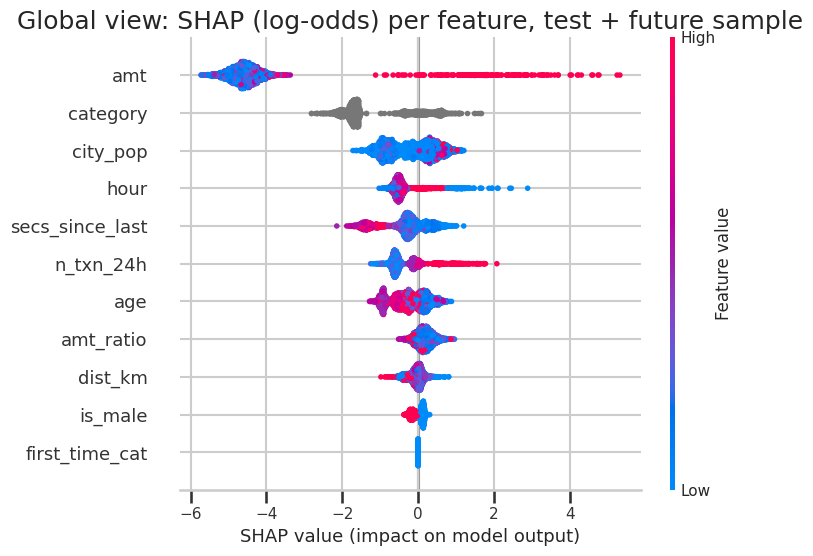

In [29]:
def group_onehot(exp: shap.Explanation, prefix: str = "cat_", name: str = "category") -> shap.Explanation:
    names = exp.feature_names
    oh = [i for i, f in enumerate(names) if f.startswith(prefix)]
    keep = [i for i in range(len(names)) if i not in oh]
    return shap.Explanation(values=np.c_[exp.values[:, keep], exp.values[:, oh].sum(1)],
                            base_values=exp.base_values,
                            data=np.c_[exp.data[:, keep], np.full(len(exp.values), np.nan)],
                            feature_names=[names[i] for i in keep] + [name])

exp = group_onehot(exp_full)
sub = np.random.default_rng(RNG).choice(len(exp.values), 4000, replace=False)
shap.plots.beeswarm(exp[sub], max_display=11, show=False)
plt.title("Global view: SHAP (log-odds) per feature, test + future sample"); plt.tight_layout(); plt.show()

**How to read it.** Each dot is a transaction; x = push towards fraud (+) or legit (−) in log-odds; colour = feature value.
The amount dominates; night hours, high velocity (`n_txn_24h`) and short gaps (`secs_since_last`) push towards fraud.

**Now the uncomfortable part.** In the synthetic generator, `city_pop`, `age` and `is_male` have **no relationship to fraud at all**,
yet they carry visible attribution. They act as a **card fingerprint**: frauds arrive in episodes on a few compromised cards,
and the trees memorise those cardholders' demographics. That is overfitting to *who was attacked in 2019*, and no
aggregate metric showed it. **SHAP doubles as a model audit**: here it exposes a spurious shortcut, and on real data it is
also the first fairness check. If a protected attribute (age, gender) carries attribution mass, that is a compliance conversation,
whether or not it improves PR-AUC. (Try challenge E6: drop them and re-measure the cost.)

### E3 · Three alerts, three stories (force plots)
We pick one **true positive**, one **false positive** and, from the future period, one **missed fraud**.

TRUE POSITIVE: p=0.997  amount=$1,801.45  Bayes threshold p*=0.008  category=shopping_net  label=fraud


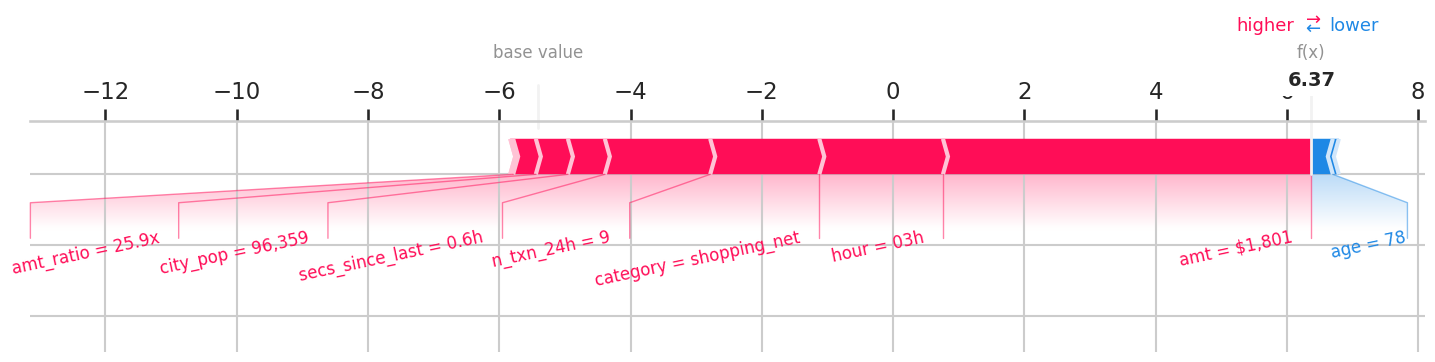

FALSE POSITIVE: p=0.979  amount=$618.06  Bayes threshold p*=0.024  category=misc_net  label=legit


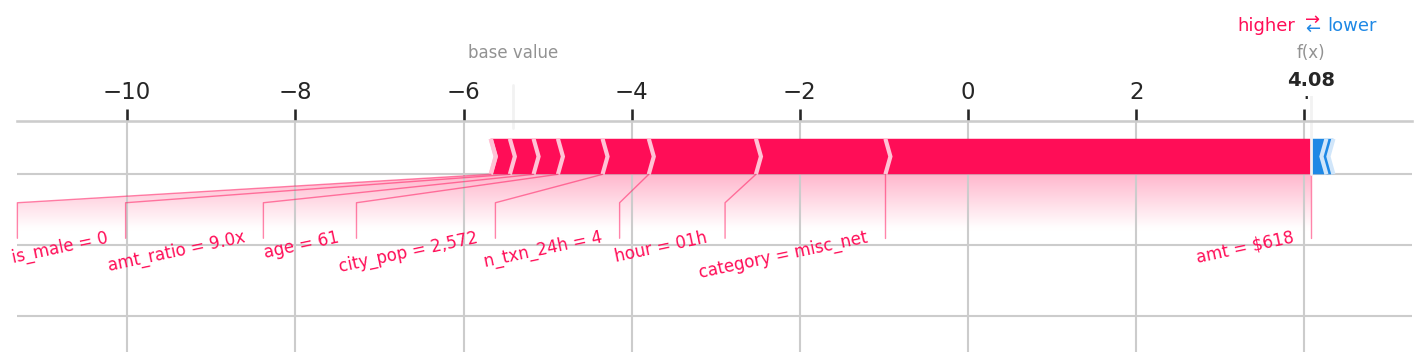

MISSED FRAUD (future): p=0.011  amount=$563.01  Bayes threshold p*=0.027  category=travel  label=fraud


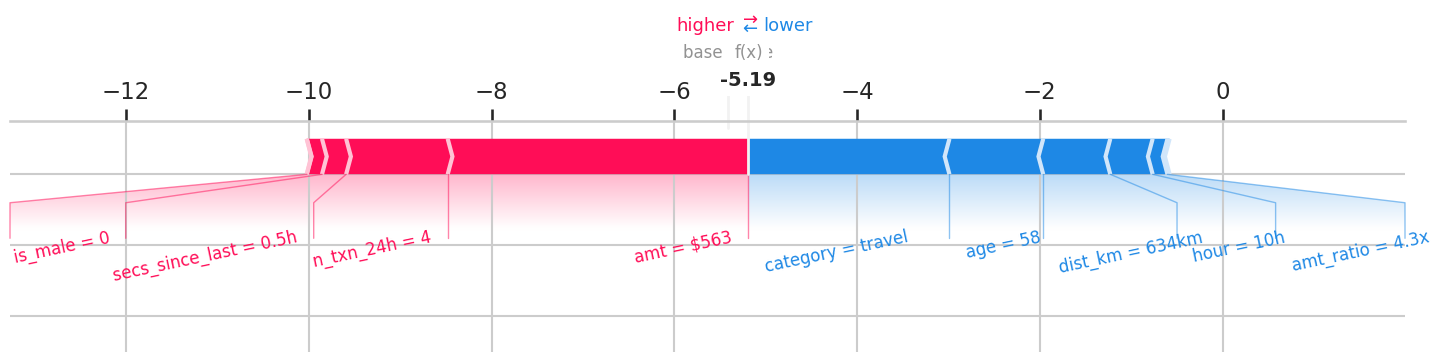

In [30]:
d_ex = data[explain_mask].reset_index(drop=True)
y_ex, amt_ex = d_ex["is_fraud"].to_numpy(), d_ex["amt"].to_numpy()
p_ex = calibrators["unweighted"](1 / (1 + np.exp(-margin)))    # production = Platt-calibrated probability
flag_ex = bayes_flag(p_ex, amt_ex)
in_test = S["test"][explain_mask]
is_B = (d_ex["fraud_mo"] == "B_day_burst").to_numpy()

i_tp = int(np.argmax(np.where(in_test & flag_ex & (y_ex == 1), p_ex, -1)))
i_fp = int(np.argmax(np.where(in_test & flag_ex & (y_ex == 0), p_ex, -1)))
fn_pool = ~in_test & ~flag_ex & (y_ex == 1) & (is_B if is_B.any() else True)
i_fn = int(np.argmax(np.where(fn_pool, amt_ex, -1)))       # the most expensive miss

def display_row(i: int) -> pd.Series:
    r = d_ex.iloc[i]
    return pd.Series({"amt": f"${r.amt:,.0f}", "amt_ratio": f"{r.amt_ratio:.1f}x", "hour": f"{r.hour:02d}h",
                      "n_txn_24h": int(r.n_txn_24h), "secs_since_last": f"{r.secs_since_last/3600:.1f}h",
                      "dist_km": f"{r.dist_km:,.0f}km", "first_time_cat": int(r.first_time_cat),
                      "age": f"{r.age:.0f}", "is_male": int(r.is_male), "city_pop": f"{r.city_pop:,}",
                      "category": r.category})

for tag, i in [("TRUE POSITIVE", i_tp), ("FALSE POSITIVE", i_fp), ("MISSED FRAUD (future)", i_fn)]:
    print(f"{tag}: p={p_ex[i]:.3f}  amount=${amt_ex[i]:,.2f}  Bayes threshold p*={C_INV/amt_ex[i]:.3f}  "
          f"category={d_ex.category[i]}  label={'fraud' if y_ex[i] else 'legit'}")
    shap.plots.force(exp.base_values[i], exp.values[i], display_row(i).values, feature_names=exp.feature_names,
                     matplotlib=True, show=False, figsize=(18, 3), text_rotation=12, contribution_threshold=0.04)
    plt.show()

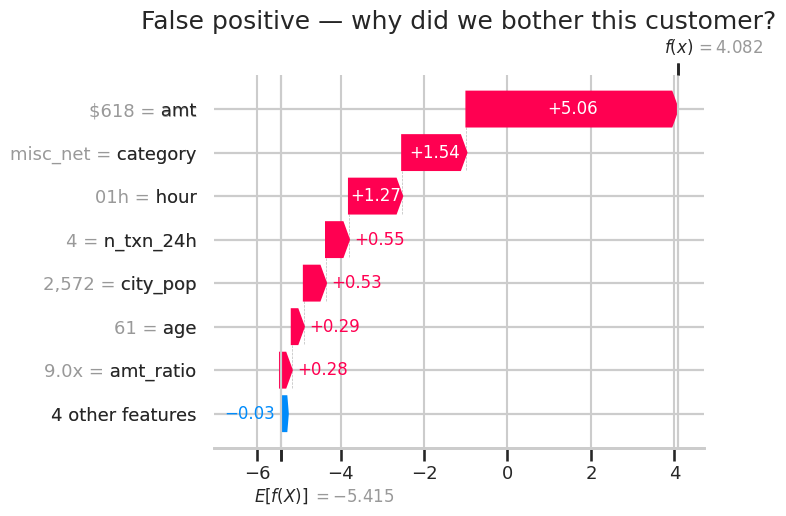

In [31]:
# The same false positive as a waterfall: easier to read for non-specialists
shap.plots.waterfall(shap.Explanation(values=exp.values[i_fp], base_values=exp.base_values[i_fp],
                                      data=display_row(i_fp).values, feature_names=exp.feature_names),
                     max_display=8, show=False)
plt.title("False positive — why did we bother this customer?"); plt.tight_layout(); plt.show()

**Business read-out.**
- **True positive:** large amount relative to the card's history, at night, in an online category. An investigator can call the customer with a concrete question.
- **False positive:** usually a legit big-ticket purchase or a habitual night shopper. The explanation tells the analyst *what to verify* (e.g. "customer often shops at night"),
  and it tells the data scientist which feature is missing (a per-card *usual hours* feature would help).
- **Missed fraud:** look at what pulls the score **down**. On the synthetic data, the amount and the velocity *do* push towards fraud, but the model
  **actively argues against** it: a `travel` merchant, far from home, in the **daytime**. In 2019 that combination meant a legitimate trip.
  That is a **drift diagnosis**: the model's knowledge is out of date, not broken, and the explanation tells you exactly which
  learned association has expired. On real data, ask the same question: which "reassuring" feature would a fraudster learn to imitate?

### E4 · ⭐ Reason codes for the case-management system (ready to run)
Investigators and audit logs need **text**, not plots. `reason_codes(i, k=3)` below returns the top-k features pushing towards
fraud (positive SHAP), each rendered as a sentence with the actual feature value.

In [32]:
TEMPLATES: dict[str, Callable[[pd.Series], str]] = {
    "amt":             lambda r: f"amount ${r.amt:,.0f}",
    "amt_ratio":       lambda r: f"amount is {r.amt_ratio:.1f}x this card's average",
    "hour":            lambda r: f"transaction at {r.hour:02d}:00",
    "n_txn_24h":       lambda r: f"{int(r.n_txn_24h)} transactions on this card in the past 24h",
    "secs_since_last": lambda r: f"only {r.secs_since_last/60:.0f} min since the previous transaction",
    "dist_km":         lambda r: f"merchant {r.dist_km:,.0f} km from the cardholder's home",
    "first_time_cat":  lambda r: "first purchase ever in this category" if r.first_time_cat else "familiar category",
    "category":        lambda r: f"merchant category '{r.category}'",
    "age":             lambda r: f"cardholder age {r.age:.0f}",
    "is_male":         lambda r: "cardholder gender",
    "city_pop":        lambda r: f"city population {r.city_pop:,}",
}

def reason_codes(i: int, k: int = 3) -> list[str]:
    r, phi = d_ex.iloc[i], exp.values[i]
    order = [j for j in np.argsort(-phi) if phi[j] > 0][:k]
    return [f"{TEMPLATES[exp.feature_names[j]](r)}  (+{phi[j]:.2f} log-odds)" for j in order]

for tag, i in [("TP", i_tp), ("FP", i_fp), ("FN", i_fn)]:
    print(f"[{tag}] p={p_ex[i]:.3f}")
    for line in reason_codes(i) or ["(nothing pushes towards fraud)"]:
        print("   •", line)

[TP] p=0.997
   • amount $1,801  (+5.61 log-odds)
   • transaction at 03:00  (+1.88 log-odds)
   • merchant category 'shopping_net'  (+1.66 log-odds)
[FP] p=0.979
   • amount $618  (+5.06 log-odds)
   • merchant category 'misc_net'  (+1.54 log-odds)
   • transaction at 01:00  (+1.27 log-odds)
[FN] p=0.011
   • amount $563  (+3.29 log-odds)
   • 4 transactions on this card in the past 24h  (+1.11 log-odds)
   • only 30 min since the previous transaction  (+0.26 log-odds)


### E5 · ⭐ Explaining the *unsupervised* alarm
Would the Isolation Forest net have caught the missed fraud above (top 0.5 % of IF scores)? And can we explain the IF's view of it?
`shap.TreeExplainer` supports Isolation Forest. It explains the **mean isolation path length** $\mathbb{E}[h(x)]$, and
`score_samples` $= -2^{-\mathbb{E}[h(x)]/c(n)}$. So **negative** SHAP = isolated faster = **more anomalous**.

IF score check: -0.631456 vs sklearn -0.631456
IF score of this txn is in the top 0.10% of the future period


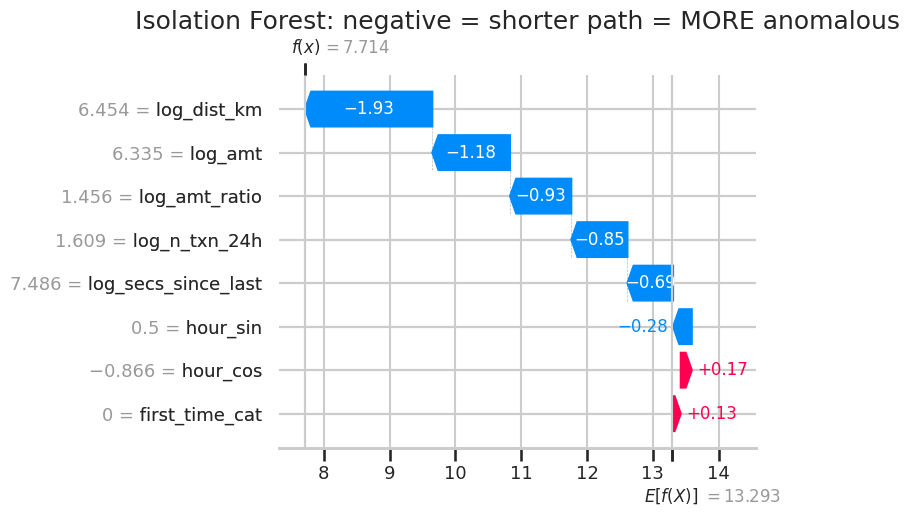

In [33]:
from sklearn.ensemble._iforest import _average_path_length   # c(n), private helper of scikit-learn
U_ex = U_all[explain_mask].reset_index(drop=True)
if_exp = shap.TreeExplainer(iso)(U_ex.iloc[[i_fn]])
# verify the stated link between SHAP's output and sklearn's score (exact up to float error)
Eh = if_exp.base_values[0] + if_exp.values[0].sum()
c_n = _average_path_length([iso.max_samples_])[0]
print(f"IF score check: {-2 ** (-Eh / c_n):.6f} vs sklearn {iso.score_samples(U_ex.iloc[[i_fn]])[0]:.6f}")
print(f"IF score of this txn is in the top {100*(if_score[S['future']] >= -iso.score_samples(U_ex.iloc[[i_fn]])[0]).mean():.2f}% of the future period")
shap.plots.waterfall(if_exp[0], max_display=8, show=False)
plt.title("Isolation Forest: negative = shorter path = MORE anomalous"); plt.tight_layout(); plt.show()

### E6 · Critical analysis — discuss
- **SHAP explains the model, not the world.** "Night pushed the score up" is a statement about the model, not a causal claim about fraud.
- **Log-odds vs. probability.** We reported additive log-odds. Converting each $\phi_j$ to "percentage points of probability" is *not* additive. Why?
- **No guarantees.** SHAP can be fooled (Slack et al., 2020), and for rich models it can provably fail to spot a spurious feature
  (Bilodeau et al., 2024, PNAS). Treat a SHAP explanation as a hypothesis to test, not as proof.
- **Fairness & shortcuts (⭐ challenge).** Drop `age`, `is_male` and `city_pop`, retrain, recalibrate, and compare the test cost
  with the card bootstrap (`card_bootstrap_diff`). Is the difference within noise? Does the leaner model do *better* on the `future` period?

---
### Where this goes next
- **Module 3 (next):** contextual anomalies & seasonality. The same "is it unusual *here and now*?" question on time series (NYC taxi demand):
  decomposition into trend / seasonality / residual, sliding-window features, a dynamic z-score vs. Isolation Forest on temporal features.
- **Project:** for your dataset, state an explicit **cost model**, report **savings** next to PR-AUC, justify your
  decision rule, and include SHAP-based **reason codes** for at least three individual alerts (TP, FP, FN).

**References:** Elkan (2001) *The Foundations of Cost-Sensitive Learning*, IJCAI · Chawla et al. (2002) *SMOTE*, JAIR ·
Saerens, Latinne & Decaestecker (2002) *Adjusting the outputs of a classifier to new a priori probabilities*, Neural Computation ·
Bahnsen, Aouada & Ottersten (2014) *Example-dependent cost-sensitive logistic regression for credit scoring*, ICMLA ·
Gama et al. (2014) *A survey on concept drift adaptation*, ACM CSUR · Dal Pozzolo et al. (2018) *Credit card fraud detection: a realistic modeling
and a novel learning strategy*, IEEE TNNLS · Lundberg & Lee (2017) *A unified approach to interpreting model predictions*, NeurIPS ·
Lundberg et al. (2020) *From local explanations to global understanding with explainable AI for trees*, Nature MI ·
Slack et al. (2020) *Fooling LIME and SHAP*, AIES · Elor & Averbuch-Elor (2022) *To SMOTE, or not to SMOTE?*, arXiv ·
van den Goorbergh et al. (2022) *The harm of class imbalance corrections for risk prediction models*, JAMIA.

**Recent work (2022–2025):** Carriero et al. (2025) *The harms of class imbalance corrections for machine learning based prediction models:
a simulation study*, arXiv:2404.19494 · Vanderschueren et al. (2022) *Predict-then-optimize or predict-and-optimize? An empirical evaluation
of cost-sensitive learning strategies*, Information Sciences 594 · Höppner et al. (2022) *Instance-dependent cost-sensitive learning for
detecting transfer fraud*, EJOR 297(1) · C-Rella, Cao & Vilar (2024) *Cost-sensitive thresholding over a two-dimensional decision region
for fraud detection*, Information Sciences 657 · Sethi et al. (2025) *Proactive detection of model degradation in financial fraud prediction
with delayed labels*, ECML-PKDD · Bilodeau et al. (2024) *Impossibility theorems for feature attribution*, PNAS 121(2) ·
Huang & Marques-Silva (2024) *On the failings of Shapley values for explainability*, IJAR 171 · McElfresh et al. (2023) *When do neural
nets outperform boosted trees on tabular data?*, NeurIPS Datasets & Benchmarks · Hollmann et al. (2025) *Accurate predictions on small
data with a tabular foundation model*, Nature 637 · Cheng et al. (2025) *Graph neural networks for financial fraud detection: a review*,
Frontiers of Computer Science 19(9).